# 00. Обзор моделей: весь путь на одной странице

**Задача:** по объявлению о вакансии предсказать месячную зарплату в сомах и диапазон, в который она попадёт.
Нужна для вакансий, где работодатель зарплату скрыл (в 2024 году 52%).

**Цель модели:** `log(зарплаты)`: распределение зарплат скошено, ошибка в процентах одинаково важна для 30 и 300 тыс.

**Метрики:** MAE в сомах (основная), медианная ошибка (типичный промах), доля прогнозов с ошибкой меньше 20%,
покрытие диапазонов.

Ноутбук только собирает итоги; подробности в ноутбуках 01–08. Запуск занимает несколько секунд.

| Этап | Данные | Проверка | Ноутбуки |
|---|---|---|---|
| 1. Модель 2024 | 5 820 вакансий hh и lalafo, февраль–март 2024 | случайные 20% + 5-кратная кросс-валидация | 01–05 |
| 2. Модель для текущего рынка | 26 892 вакансии 2024–2026 (мастер-датасет) | обучение до июля 2026, тест июль–октябрь 2026 | 07 |
| 3. Улучшения | те же | настройки на апреле–июне, тест один раз | 08 |

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

FIG = "../reports/figures/"
fmt = lambda df: df.style.format({c: "{:,.0f}" for c in df.columns if pd.api.types.is_numeric_dtype(df[c])}).hide(axis="index")

## Этап 1. Данные 2024 года: какой тип модели лучше

Сначала базовая линия (медиана профессии), потом 13 моделей разных семейств на одном разбиении. Пустые ячейки: модель оценивалась только кросс-валидацией.

In [2]:
nan = float("nan")
stage1 = pd.DataFrame([
    ["Медиана профессии (базовая линия)", "простое правило", 17718, 17793, "01"],
    ["Ridge на признаках", "линейная", 17344, 17512, "01–02"],
    ["LightGBM на признаках", "бустинг деревьев", 17247, 17544, "02"],
    ["Random Forest", "лес деревьев", 17122, 18037, "02"],
    ["CatBoost на признаках", "бустинг деревьев", 16888, 17112, "02"],
    ["kNN (15 похожих вакансий)", "по похожести", 16841, nan, "05"],
    ["Huber", "линейная, устойчивая к выбросам", 16528, nan, "05"],
    ["LightGBM на признаках + тексте", "бустинг деревьев", 16331, nan, "05"],
    ["CatBoost с текстом", "бустинг деревьев", 16138, nan, "05"],
    ["Linear SVR", "линейная", 15786, 16291, "05"],
    ["Ridge + TF-IDF текста", "линейная + текст", 16246, 16249, "02"],
    ["Ridge + TF-IDF, Optuna (финальная 2024)", "линейная + текст", 15610, 15763, "03"],
    ["Смесь Ridge + CatBoost", "смесь", 15534, 15755, "05"],
], columns=["модель", "семейство", "MAE, кросс-валидация", "MAE, тест", "ноутбук"])
stage1.sort_values("MAE, кросс-валидация", ascending=False).style.format(
    {"MAE, кросс-валидация": "{:,.0f}", "MAE, тест": "{:,.0f}"}, na_rep="").hide(axis="index")

модель,семейство,"MAE, кросс-валидация","MAE, тест",ноутбук
Медиана профессии (базовая линия),простое правило,"17,718","17,793",01
Ridge на признаках,линейная,"17,344","17,512",01–02
LightGBM на признаках,бустинг деревьев,"17,247","17,544",02
Random Forest,лес деревьев,"17,122","18,037",02
CatBoost на признаках,бустинг деревьев,"16,888","17,112",02
kNN (15 похожих вакансий),по похожести,"16,841",,05
Huber,"линейная, устойчивая к выбросам","16,528",,05
LightGBM на признаках + тексте,бустинг деревьев,"16,331",,05
Ridge + TF-IDF текста,линейная + текст,"16,246","16,249",02
CatBoost с текстом,бустинг деревьев,"16,138",,05


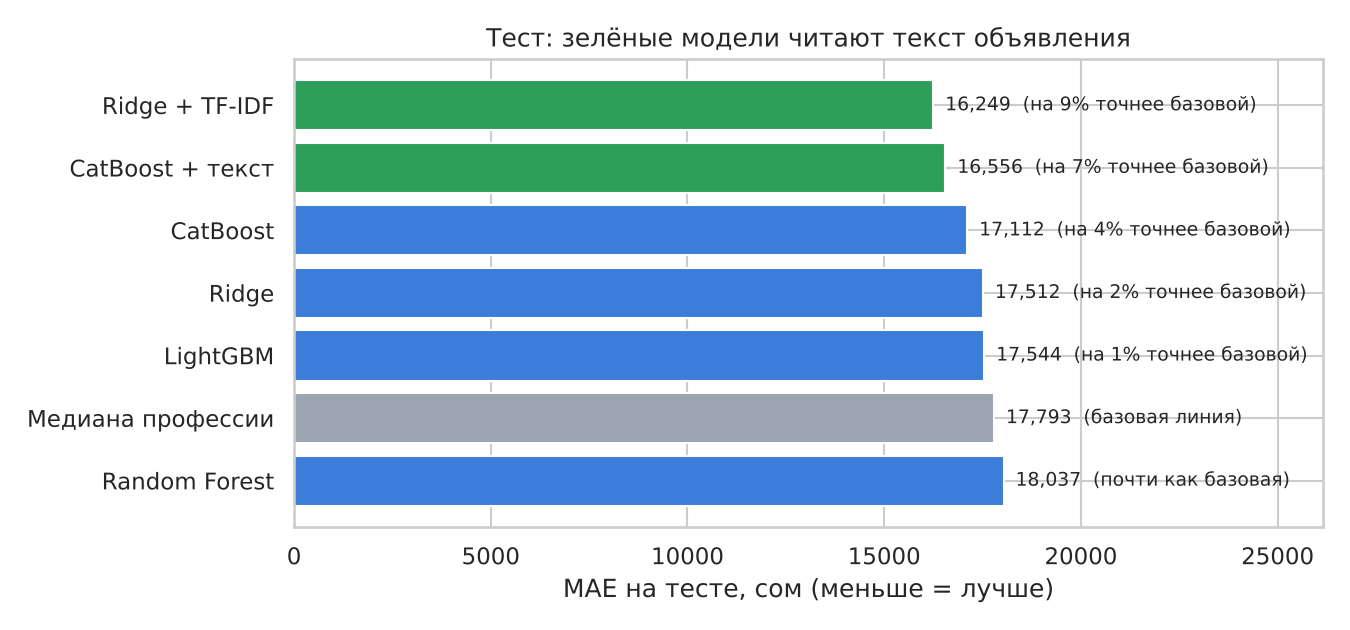

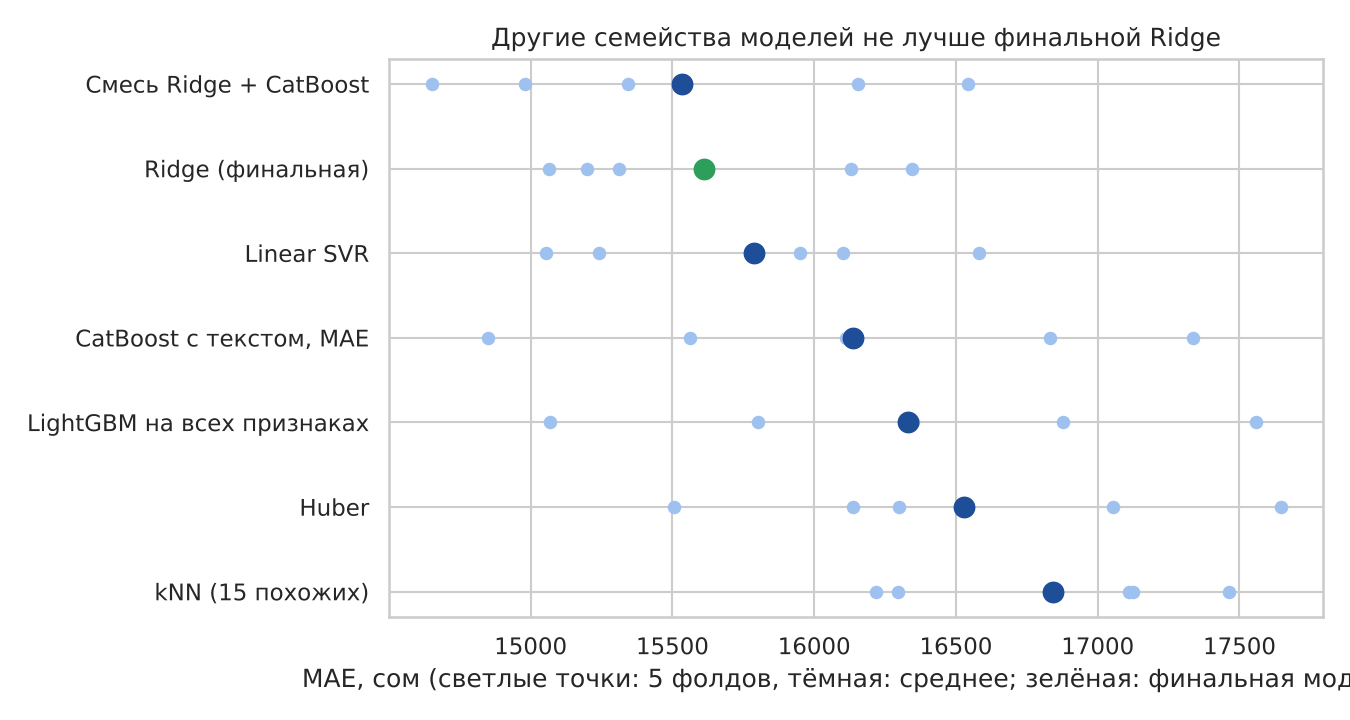

In [3]:
display(Image(FIG + "02_test.png", width=750))
display(Image(FIG + "05_more_models.png", width=750))

**Вывод этапа 1:** текст объявления важнее сложности модели. Бустинг на полях почти не лучше медианы профессии,
а линейная модель с текстом (TF-IDF) снижает ошибку на 11%. Все сильные модели упираются в ~15,5–16 тыс.:
одинаковые заголовки различаются по зарплате на ~12 тыс. сом. Нейросетевые эмбеддинги (rubert-tiny2) подготовлены
в ноутбуке 06.

**Проблема:** модель обучена на феврале–марте 2024, а зарплаты с тех пор выросли.

## Этап 2. Модель для текущего рынка (ноутбук 07)

Данные: мастер-датасет 2024–2026 (hh, lalafo и Telegram-каналы по единым правилам; неуказанный опыт не подставляется). Проверка **по времени**: обучение только на прошлом,
тест на вакансиях июля–октября 2026. Повторные объявления того же работодателя из теста удалены.

In [4]:
stage2 = pd.DataFrame([
    ["Медиана профессии за последние 6 месяцев", 29808, 20000, "−5%"],
    ["A. Модель 2024 без переобучения", 38210, 24026, "−36%"],
    ["B. Ridge + TF-IDF, обучение 2024–2026", 26877, 16704, "−9%"],
    ["C. + месяц публикации", 26620, 16841, "−2%"],
    ["D. + работодатель", 25471, 15742, "−1%"],
    ["F. + уровень (junior…lead), сфера × опыт", 25431, 15898, "−1%"],
], columns=["модель", "MAE, сом", "медианная ошибка, сом", "смещение"])
fmt(stage2)

модель,"MAE, сом","медианная ошибка, сом",смещение
Медиана профессии за последние 6 месяцев,"29,808","20,000",−5%
A. Модель 2024 без переобучения,"38,210","24,026",−36%
"B. Ridge + TF-IDF, обучение 2024–2026","26,877","16,704",−9%
C. + месяц публикации,"26,620","16,841",−2%
D. + работодатель,"25,471","15,742",−1%
"F. + уровень (junior…lead), сфера × опыт","25,431","15,898",−1%


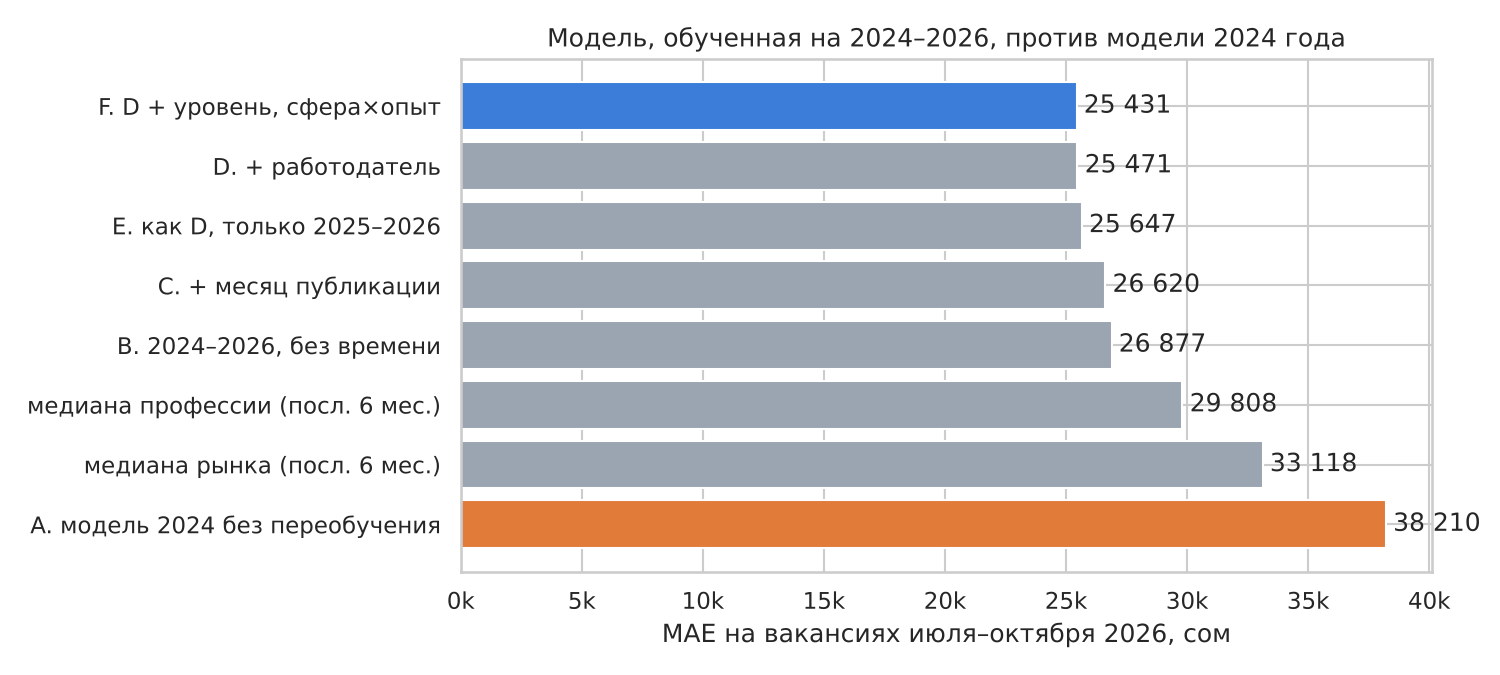

In [5]:
display(Image(FIG + "07_time_models.png", width=750))

**Вывод этапа 2:** модель 2024 года занижает сегодняшние зарплаты на треть. Переобучение на 2024–2026 с признаком
времени убирает перекос. F выбрана вместо D при той же точности: опыт в ней влияет как на рынке.

## Этап 3. Улучшения (ноутбук 08)

Настройки выбраны на валидации (апрель–июнь 2026), тест открыт один раз.

In [6]:
stage3 = pd.DataFrame([
    ["F из ноутбука 07", 25431, 15905],
    ["+ формат вакансии (поле «Тип»: office, remote…)", 25402, 15891],
    ["+ поля «Тип» и «Дополнительно» в тексте", 25393, 15860],
    ["+ больший вес свежих вакансий (полураспад 6 мес.)", 24753, 15372],
    ["+ смесь с LightGBM (40%), финальная модель", 24248, 14691],
], columns=["шаг", "MAE, сом", "медианная ошибка, сом"])
stage3["к модели F"] = (stage3["MAE, сом"] / stage3["MAE, сом"].iloc[0] - 1).map("{:+.1%}".format)
fmt(stage3)

шаг,"MAE, сом","медианная ошибка, сом",к модели F
F из ноутбука 07,"25,431","15,905",+0.0%
"+ формат вакансии (поле «Тип»: office, remote…)","25,402","15,891",-0.1%
+ поля «Тип» и «Дополнительно» в тексте,"25,393","15,860",-0.1%
+ больший вес свежих вакансий (полураспад 6 мес.),"24,753","15,372",-2.7%
"+ смесь с LightGBM (40%), финальная модель","24,248","14,691",-4.7%


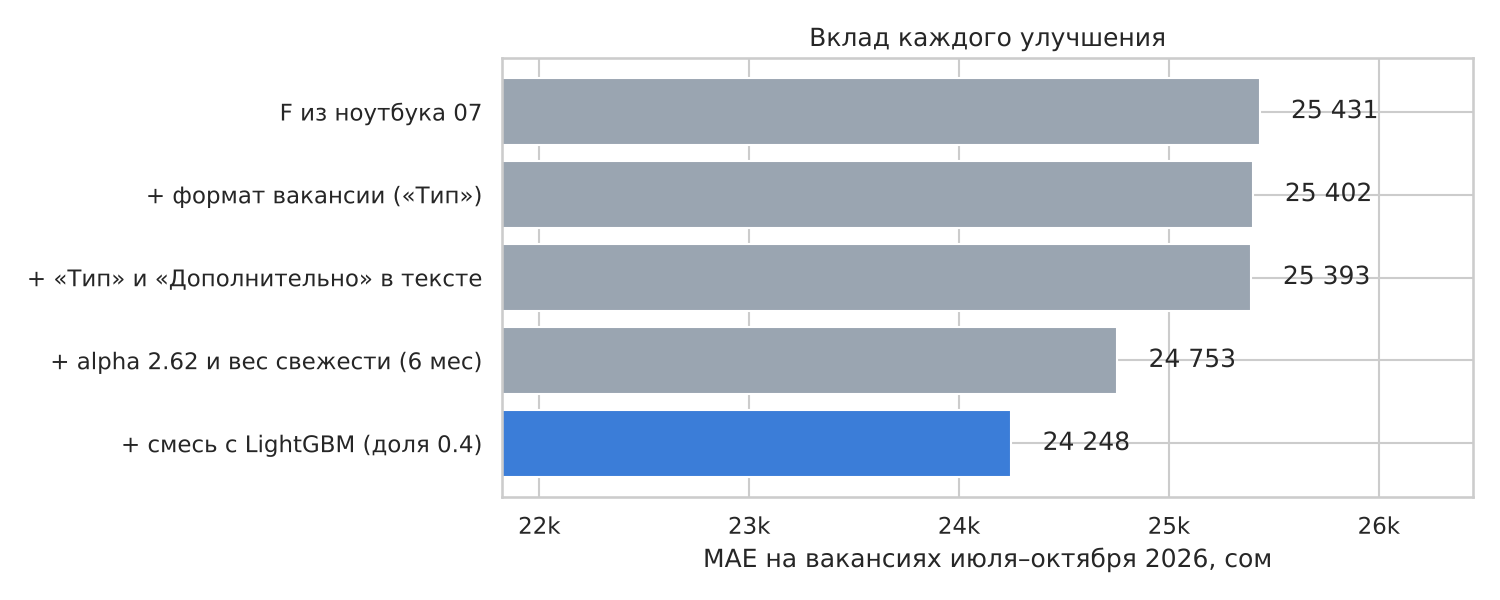

In [7]:
display(Image(FIG + "08_steps.png", width=750))

## Финальная модель на тесте

Прогнозы ниже пересчитаны скриптом `src/make_app_data.py` (модель обучена до июля 2026) и сохранены
в `reports/app/test_predictions.csv`. У каждой вакансии есть ссылка на исходный пост.

In [8]:
S = json.load(open("../reports/app/summary.json", encoding="utf-8"))
t = pd.read_csv("../reports/app/test_predictions.csv")
pd.Series({
    "вакансий в тесте": f"{S['n_test']:,}".replace(",", " "),
    "медианная ошибка": f"{S['median_error']:,.0f} сом".replace(",", " "),
    "средняя ошибка (MAE)": f"{S['mae']:,.0f} сом".replace(",", " "),
    "ошибка меньше 20%": f"{S['within20']:.0%}",
    "попало в 50% диапазон": f"{S['coverage50']:.0%}",
    "попало в 80% диапазон": f"{S['coverage80']:.0%}",
}).to_frame("значение")

,значение
вакансий в тесте,2 020
медианная ошибка,14 691 сом
средняя ошибка (MAE),24 248 сом
ошибка меньше 20%,45%
попало в 50% диапазон,50%
попало в 80% диапазон,80%


In [9]:
t["уровень зарплаты"] = pd.cut(t["реальная зарплата"], [0, 25e3, 40e3, 60e3, 100e3, 1e9],
                               labels=["до 25 тыс.", "25–40 тыс.", "40–60 тыс.", "60–100 тыс.", "больше 100 тыс."])
seg = t.groupby("уровень зарплаты", observed=True).agg(
    вакансий=("прогноз", "size"), медианная_ошибка=("ошибка, сом", "median"),
    в_80_диапазоне=("в 80% диапазоне", "mean"))
seg.style.format({"медианная_ошибка": "{:,.0f}", "в_80_диапазоне": "{:.0%}"})

,вакансий,медианная_ошибка,в_80_диапазоне
уровень зарплаты,,,
до 25 тыс.,60,"22,000",30%
25–40 тыс.,318,"13,500",70%
40–60 тыс.,564,"9,000",95%
60–100 тыс.,701,"13,000",91%
больше 100 тыс.,377,"49,400",55%


In [10]:
print("Пять последних вакансий теста:")
t[["дата", "вакансия", "работодатель", "реальная зарплата", "прогноз", "80% от", "80% до"]].head(5)

Пять последних вакансий теста:


,дата,вакансия,работодатель,реальная зарплата,прогноз,80% от,80% до
0,2026-10-28,Руководитель филиала,азия бренд плюс,85000.0,73000.0,42000.0,120000.0
1,2026-10-28,Менеджер,осоо sunrise travel (санрайз тревел),87500.0,77000.0,45000.0,128000.0
2,2026-10-28,СММ специалист,осоо шанхай групп,50000.0,39000.0,23000.0,65000.0
3,2026-10-28,Системный администратор,осоо мега-лайн,55000.0,46000.0,27000.0,76000.0
4,2026-10-28,Менеджер по активным продажам,наши окна,150000.0,108000.0,63000.0,180000.0


## Итог

1. **Пройденный путь:** медиана профессии → 13 моделей на данных 2024 → переобучение на мастер-датасете 2024–2026
   с проверкой по времени → улучшения. Ошибка на текущем рынке снижена с 38 210 (модель 2024) до **24 248 сом** MAE,
   типичный промах **14 691 сом** (около 23% зарплаты).
2. **Точнее всего для типичных зарплат:** 40–60 тыс., медианная ошибка около 9 000 сом.
3. **Диапазоны надёжны:** 80% диапазон накрыл 80% реальных зарплат на будущих вакансиях.
4. **Предел данных:** одинаковые заголовки у разных работодателей различаются на 25%, поэтому ошибка
   меньше ~20% для одной вакансии недостижима по тексту объявления.
5. **Дальше:** нейросеть (ноутбук 06), отдельная модель для IT, новые источники данных.

**Приложение:** `streamlit run app.py` (данные, прогноз для любой вакансии, точность, проверка на свежих вакансиях).